# Experiment 1: Finding the better basin
Keep this notebook beside `methods.ipynb` and `configurations.ipynb`. 

## Objective and search domain

For $x \in [-4,4]^2$ and $c \ge 0$, minimise

$$
f_c(x) = \min\left\{
    1 + \lVert x-a \rVert_2^2,\;
    \lVert x-b \rVert_2^2
    + c\left[\max\left(0, \lVert x-b \rVert_2 - 0.5\right)\right]^2
\right\},
\qquad a = (-2,0),\quad b = (2,0).
$$

Basin A has a local minimum of 1 at $a$. Basin B has the global minimum of 0 at $b$. Increasing $c$ shrinks the region where $f_c(x)<1$ and increase the gradient of Basin B outside its center (circle of radius 0.25 around the global minimum).  

## 1. Setup

Install the dependencies in the notebook's Python environment before
running the experiment. The second command needs Git and network access.

```python
%pip install numpy pandas scipy matplotlib scikit-optimize cma torch gpytorch
%pip install git+https://github.com/uber-research/TuRBO.git
```

The next cell imports the analysis and plotting libraries, import the definitions in `methods.ipynb` and `configurations.ipynb`, and assigns one colour and marker to each method. 

In [1]:
from datetime import datetime, timezone
from itertools import product
import json
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest

NOTEBOOK_DIR = Path("code") if Path("code/methods.ipynb").is_file() else Path(".")
RESULTS_ROOT = NOTEBOOK_DIR / "results" / "experiment_1"

def load_definition_notebook(path):
    notebook = json.loads(path.read_text(encoding="utf-8"))

    for cell in notebook["cells"]:
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])
            exec(source, globals())

load_definition_notebook(NOTEBOOK_DIR / "methods.ipynb")
load_definition_notebook(NOTEBOOK_DIR / "configurations.ipynb")

METHOD_STYLES = {
    "BO": ("tab:blue", "o"),
    "CMA-ES": ("tab:orange", "s"),
    "TuRBO-1": ("tab:green", "^"),
    "Random": ("tab:red", "D"),
}

## 2. Run through the penalty values

The next cell defines `run_iteration`. It iterates every configured penalty, seed, and method, constructs the corresponding objective, and runs that method with the  budget. 

The function collects the complete set of trials and writes `results.json` once after the iteration finishes. A new directory under `code/results/experiment_1/` keeps the information for that execution. The saved data is used for the geometry and run settings needed by the later plots.

In [2]:
def run_iteration(settings, results_root):
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run_dir = results_root / stamp
    run_dir.mkdir(parents=True)
    results = {"configuration": {"run": settings}, "runs": []}
    jobs = product(settings["c_values"], settings["seeds"], settings["methods"])
    for c, seed, method in jobs:
        outcome = run_method(method, make_objective(c), DOMAIN_BOUNDS,
                             settings["budget"], seed, METHOD_PARAMS[method])
        results["runs"].append({
            "c": c, "seed": seed, "method": method,
            "X": outcome["X"].tolist(), "y": outcome["y"].tolist(),
            "diagnostics": outcome["diagnostics"],
        })
    (run_dir / "results.json").write_text(json.dumps(results), encoding="utf-8")
    return results, run_dir

The next cell starts the configured iteration and returns both its histories and output directory. 

In [3]:
results, run_dir = run_iteration(RUN_SETTINGS, RESULTS_ROOT)

c:\Users\Brian Bong Neng Ye\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 3. Overview of performance

The bar chart shows the same runs based on their tightest target. Median best is computed across all seeds, including runs that missed B.

- **Discovery** means the run reached $f<1$ and beat basin A's minimum.
- **Center entry** means it reached $f<0.25$, inside the fixed center of basin B.
- **Refinement** means it reached $f<10^{-2}$ or the tighter $f<10^{-4}$.

The next cell defines three helpers. `target_trials` creates one row per run and target, recording whether the target was reached, the first successful call, and the best value from the full run. `summarise_targets` aggregates those rows over seeds and computes 95% confidence intervals for the success fractions. `search_diagnostics` combines discovery calls with the fraction of late evaluations near A and the CMA-ES restart counts.

Missing first-success values mean that the target was never reached within the budget. The median first-success statistic is conditional on reaching that target, whereas median best objective uses all runs in the condition. `calls_after_discovery` is the number of evaluations left after the first value below 1.


In [4]:
def target_trials(results, targets):
    """Return one row per trajectory and objective target."""
    rows = []
    for run in results["runs"]:
        c_value, seed, method = run["c"], run["seed"], run["method"]
        values = np.asarray(run["y"])
        for target in targets:
            hits = np.flatnonzero(values < target)
            rows.append({
                "c": c_value, "seed": seed, "method": method, "target": target,
                "success": bool(hits.size),
                "first_success": int(hits[0]) + 1 if hits.size else np.nan,
                "best": values.min(),
            })
    return pd.DataFrame(rows)


def summarise_targets(trials):
    # aggregate seeds separately for each penalty, method, and target.
    summary = trials.groupby(["c", "method", "target"], sort=False).agg(
        runs=("success", "size"),
        successes=("success", "sum"),
        success_probability=("success", "mean"),
        median_first_success_given_success=("first_success", "median"),
        median_best=("best", "median"),
    ).reset_index()

    # confidence intervals describing uncertainty in each observed success fraction across seeds
    intervals = [binomtest(int(row.successes), int(row.runs)).proportion_ci(method="wilson")
                 for row in summary.itertuples()]
    summary["confidence_interval_low"] = [interval.low for interval in intervals]
    summary["confidence_interval_high"] = [interval.high for interval in intervals]
    return summary


def search_diagnostics(results, trials, settings):
    """Return trajectory data, with one row per completed run."""
    runs = results["configuration"]["run"]
    centre_a = np.asarray(runs["problem"]["a"])
    late_evaluations = settings["late_evaluations"]
    rows = []
    for run in results["runs"]:
        c_value, seed, method = run["c"], run["seed"], run["method"]

        # calculate one distance from basin A for every evaluated point.
        distance = np.linalg.norm(np.asarray(run["X"]) - centre_a, axis=1)
        rows.append({
            "c": c_value, "seed": seed, "method": method,

            # use only the final calls to measure whether the search stayed near the inferior basin.
            "late_near_a": np.mean(distance[-late_evaluations:] <= settings["near_a_radius"]),
            "restarts": run["diagnostics"].get("restarts", np.nan),
        })

    discoveries = trials.loc[trials["target"] == 1.0, [
        "c", "seed", "method", "success", "first_success", "best"
    ]].rename(columns={"success": "discovered", "first_success": "first_discovery"})
    diagnostics = pd.DataFrame(rows).merge(discoveries, on=["c", "seed", "method"])
    diagnostics["calls_after_discovery"] = runs["budget"] - diagnostics["first_discovery"]
    return diagnostics

### Define the outcome chart

For each method and penalty, the chart places every seed in one of five categories: missed B, discovered B without entering the center, entered the center without reaching 0.01, reached 0.01 without reaching 0.0001, or reached 0.0001.

In [5]:
from matplotlib.ticker import PercentFormatter

def save_figure(fig, run_dir, filename):
    plot_dir = run_dir / "plots"
    plot_dir.mkdir(exist_ok=True)
    fig.savefig(plot_dir / filename, dpi=140, bbox_inches="tight")
    plt.show()


def plot_outcome_breakdown(summary, settings, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    rates = summary.pivot(index=["c", "method"], columns="target",
                          values="success_probability")
    targets = ANALYSIS_SETTINGS["targets"]
    tiers = [
        ("Missed correct basin", "0.83"), ("Entered correct basin", "#c6dbef"),
        ("Entered center", "#9ecae1"), ("Reached 0.01", "#4292c6"),
        ("Reached 0.0001", "#08519c"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(11, 6.8), sharex=True)
    for ax, c_value in zip(axes.flat, penalties):
        cumulative = rates.loc[c_value].reindex(index=methods, columns=targets).to_numpy()
        # Add 100% and 0% endpoints; adjacent differences turn nested targets into exclusive tiers.
        edges = np.column_stack([np.ones(len(methods)), cumulative, np.zeros(len(methods))])
        widths = -np.diff(edges, axis=1)
        for i, (label, color) in enumerate(tiers):
            # Stack each tier from left to right so every method's bar totals 100%.
            ax.barh(methods, widths[:, i], left=1 - edges[:, i], color=color,
                    edgecolor="white", linewidth=0.5, label=label)
        ax.set(title=f"c = {c_value:g}", xlim=(0, 1))
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)
    # Hide unused panels when the number of penalties does not fill the subplot grid.
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", frameon=False, ncol=3)
    fig.suptitle("Cumulative breakdown of outcomes across all runs")
    fig.tight_layout(rect=(0, 0.12, 1, 0.94))
    save_figure(fig, run_dir, "outcome_breakdown.png")

### Calculate and display the overview

The next cell builds the trial, summary, and diagnostic tables, then displays the target counts and median best objective for every penalty/method combination. It also draws the outcome chart defined above and saves the numerical tables as CSV files.

Beat A Entered center f < 0.01 f < 0.0001 Median best
c    method                                                       
0.0  BO        9/10           9/10     9/10       7/10   1.112e-05
     CMA-ES    9/10           6/10     2/10       1/10     0.03541
     TuRBO-1   9/10           9/10     9/10       3/10   0.0003411
     Random   10/10           6/10     1/10       0/10       0.188
3.0  BO        5/10           5/10     5/10       2/10      0.5016
     CMA-ES    9/10           8/10     2/10       0/10     0.08434
     TuRBO-1   5/10           5/10     5/10       0/10      0.5013
     Random   10/10           6/10     1/10       0/10       0.188
10.0 BO        2/10           2/10     2/10       1/10           1
     CMA-ES    7/10           4/10     2/10       0/10      0.4735
     TuRBO-1   2/10           2/10     2/10       0/10           1
     Random    9/10           6/10     1/10       0/10       0.188
30.0 BO        1/10           1/10     1/10       0/10           1
     CMA-ES    5/10           5/10     0/10       0/10      0.5561
     TuRBO-1   1/10           1/10     0/10       0/10           1
     Random    8/10           6/10     1/10       0/10       0.188

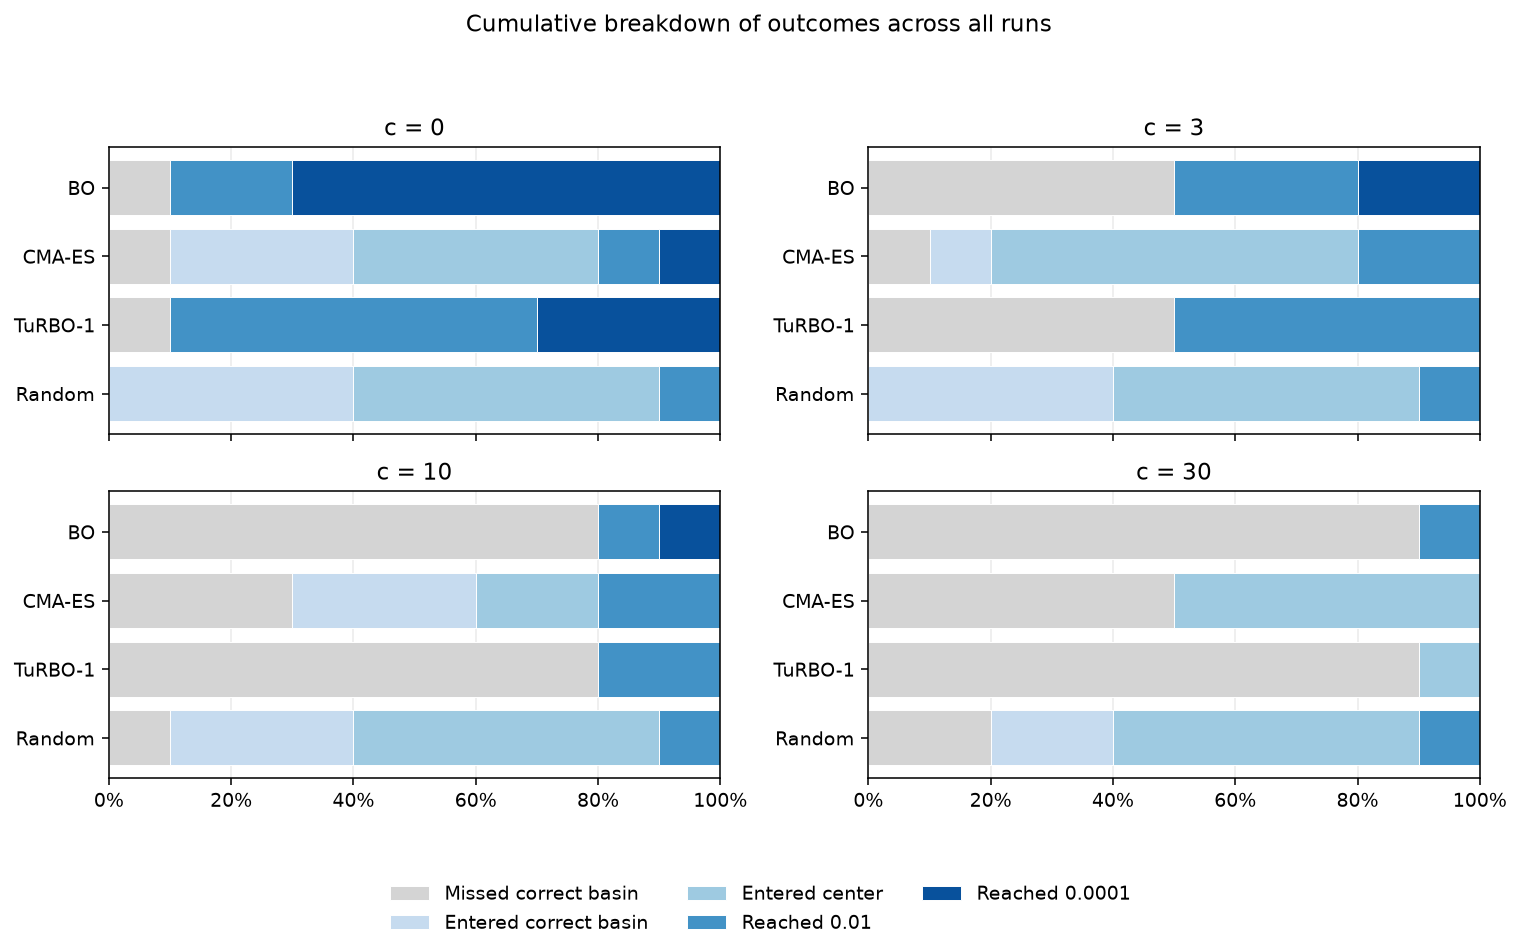

In [6]:
# build rows, aggregate success rates, and derive per-trial search data.
trials = target_trials(results, ANALYSIS_SETTINGS["targets"])
summary = summarise_targets(trials)
diagnostics = search_diagnostics(results, trials, ANALYSIS_SETTINGS)

order = pd.MultiIndex.from_product([RUN_SETTINGS["c_values"], RUN_SETTINGS["methods"]],
                                   names=["c", "method"])
counts = summary.pivot(index=["c", "method"], columns="target", values="successes")
counts = counts.reindex(index=order, columns=ANALYSIS_SETTINGS["targets"])
sizes = summary.groupby(["c", "method"])["runs"].first().reindex(order)

overview = counts.astype(str).add("/" + sizes.astype(str), axis="index")
overview.columns = ["Beat A", "Entered center", "f < 0.01", "f < 0.0001"]

overview["Median best"] = diagnostics.groupby(["c", "method"])["best"].median().reindex(order)
display(overview.assign(**{"Median best": overview["Median best"].map("{:.4g}".format)}))

trials.to_csv(run_dir / "trials.csv", index=False)
summary.to_csv(run_dir / "summary.csv", index=False)
diagnostics.to_csv(run_dir / "diagnostics.csv", index=False)
overview.to_csv(run_dir / "overview.csv")

plot_outcome_breakdown(summary, RUN_SETTINGS, run_dir)

**Interpretation**: The methods differ in both their probability of entering the better basin and the precision
they achieve afterwards. At c = 0, BO, CMA-ES and TuRBO-1 each beat A in 9 of 10 runs. BO and TuRBO-1 reach f < 0.01 in all nine successful runs, while CMA-ES reaches that target in two runs, indicating more successful refinement by BO and TuRBO-1 in these trials.

At c = 10, CMA-ES beats A in seven runs, compared with two for BO and TuRBO-1. Nevertheless, all three methods reach f < 0.01 in two runs. CMA-ES reaches the better region more frequently, while BO and TuRBO-1 achieve greater precision in the runs where they beat A.

## 4. Comparison between different methods

The next cell defines three plotting functions. The first figure has one panel for each of the four objective targets, showing how the fraction of successful seeds changes with $c$.

The second figure has discovery curves in its top row and best-so-far objective curves in its bottom row. Discovery curves show the fraction of all seeds that have reached $f<1$ by each call. The best-so-far curves show the median and interquartile range across all seeds. The dashed horizontal line marks the value 1 at A's minimum.

The third figure show, for each group, the average share of the final 20 evaluations within distance 1 of A. The accompanying table reports group sizes because some groups contain only one or two seeds.

In [7]:
def plot_target_rates(summary, settings, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    targets = ANALYSIS_SETTINGS["targets"]
    spacing = min(np.diff(penalties))

    # slight horizontal offsets separate datapoints plotted at the same penalty
    offsets = np.linspace(-0.18, 0.18, len(methods)) * spacing

    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
    for ax, target in zip(axes.flat, targets):
        part = summary.loc[summary["target"] == target].set_index(["c", "method"])
        for method, offset in zip(methods, offsets):
            color, marker = METHOD_STYLES[method]
            rates = part.xs(method, level="method").reindex(penalties)["success_probability"]
            ax.plot(np.asarray(penalties) + offset, rates, color=color, marker=marker,
                    label=method, linewidth=1.4)
        ax.set(title=f"$f < {target:g}$", xlabel="Penalty c", ylabel="Fraction of successful runs",
               xticks=penalties, ylim=(-0.05, 1.05))
        ax.grid(alpha=0.3)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f"Success rates after {settings['budget']} calls")
    fig.tight_layout()
    save_figure(fig, run_dir, "targets_by_c.png")


def plot_progress(results, diagnostics, settings, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    budget = settings["budget"]
    calls = np.arange(1, budget + 1)
    histories = {(c, method): [] for c, method in product(penalties, methods)}
    for run in results["runs"]:
        histories[run["c"], run["method"]].append(np.minimum.accumulate(run["y"]))

    fig, axes = plt.subplots(2, len(penalties), figsize=(4 * len(penalties), 6.7),
                             sharex=True, sharey="row", squeeze=False)
    for column, c_value in enumerate(penalties):
        ax_hit, ax_best = axes[:, column]
        for method in methods:
            color, marker = METHOD_STYLES[method]
            first = diagnostics.loc[
                (diagnostics["c"] == c_value) & (diagnostics["method"] == method),
                "first_discovery",
            ].to_numpy()

            cumulative = (first[:, None] <= np.arange(budget + 1)).mean(axis=0)
            ax_hit.step(np.arange(budget + 1), cumulative, where="post", color=color, label=method)
            ax_hit.scatter(budget, cumulative[-1], color=color, marker=marker, s=20)

            lower, median, upper = np.quantile(histories[c_value, method], [0.25, 0.5, 0.75], axis=0)
            ax_best.step(calls, median, where="post", color=color)
            ax_best.fill_between(calls, lower, upper, step="post", color=color, alpha=0.15)

        ax_hit.set(title=f"c = {c_value:g}", xlim=(0, budget + 1), ylim=(-0.03, 1.03))
        ax_best.axhline(1, color="black", linestyle="--", linewidth=0.9)
        ax_best.set(xlabel="Objective evaluations", ylim=(0, None))

        ax_best.set_yscale("symlog", linthresh=1e-5)
        for ax in (ax_hit, ax_best):
            ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel("Fraction of runs that discovered B")
    axes[1, 0].set_ylabel("Median best-so-far objective")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, run_dir, "discovery_and_progress.png")


def plot_concentration(concentration, settings, analysis, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    spacing = min(np.diff(penalties))
    offsets = np.linspace(-0.18, 0.18, len(methods)) * spacing

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
    for ax, discovered in zip(axes, (False, True)):
        by_outcome = concentration.loc[concentration["discovered"] == discovered]
        for method, offset in zip(methods, offsets):
            color, marker = METHOD_STYLES[method]
            near_a = by_outcome.loc[by_outcome["method"] == method].set_index("c")
            rates = near_a["mean_late_near_a"].reindex(penalties)
            ax.plot(np.asarray(penalties) + offset, rates, color=color, marker=marker,
                    label=method, linewidth=1.4)
        ax.set(title="Discovered B" if discovered else "Missed B", xlabel="Penalty c",
               xticks=penalties, ylim=(-0.05, 1.05))
        ax.grid(alpha=0.3)
    n = analysis["late_evaluations"]
    radius = analysis["near_a_radius"]
    axes[0].set_ylabel(f"Fraction of final {n} evaluations within {radius:g} of A")
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, run_dir, "near_basin_a.png")

The next cell groups the run-level diagnostics by penalty, method, and discovery outcome. The concentration table reports each group's number of runs, mean late concentration near A, and median final best value. The refinement table includes discovered runs and reports how many reached 0.01, the median discovery call, how many calls remained, and how many discoveries occurred after half the budget (call 25 with the current settings).

The CMA-ES message reports how many trials restarted at least once. The three figures then show target success rates, discovery and objective progress, and late concentration near A. All use the same saved trajectories. The three interpretations following the cell refer to these figures in that order.

CMA-ES started again in 0/40 runs.


,c,method,discovered,runs,mean_late_near_a,median_best
0,0.0,BO,False,1,0.850000,1.000184
1,0.0,BO,True,9,0.016667,0.000009
2,0.0,CMA-ES,False,1,0.450000,1.075840
3,0.0,CMA-ES,True,9,0.038889,0.029974
4,0.0,Random,True,10,0.050000,0.188032
5,0.0,TuRBO-1,False,1,0.800000,1.000228
6,0.0,TuRBO-1,True,9,0.011111,0.000324
7,3.0,BO,False,5,0.830000,1.000076
8,3.0,BO,True,5,0.010000,0.000228
9,3.0,CMA-ES,False,1,0.450000,1.081935


discoveries  ...  reached_0_01
c    method                ...              
0.0  BO                 9  ...             9
     CMA-ES             9  ...             2
     Random            10  ...             1
     TuRBO-1            9  ...             9
3.0  BO                 5  ...             5
     CMA-ES             9  ...             2
     Random            10  ...             1
     TuRBO-1            5  ...             5
10.0 BO                 2  ...             2
     CMA-ES             7  ...             2
     Random             9  ...             1
     TuRBO-1            2  ...             2
30.0 BO                 1  ...             1
     CMA-ES             5  ...             0
     Random             8  ...             1
     TuRBO-1            1  ...             0

[16 rows x 5 columns]

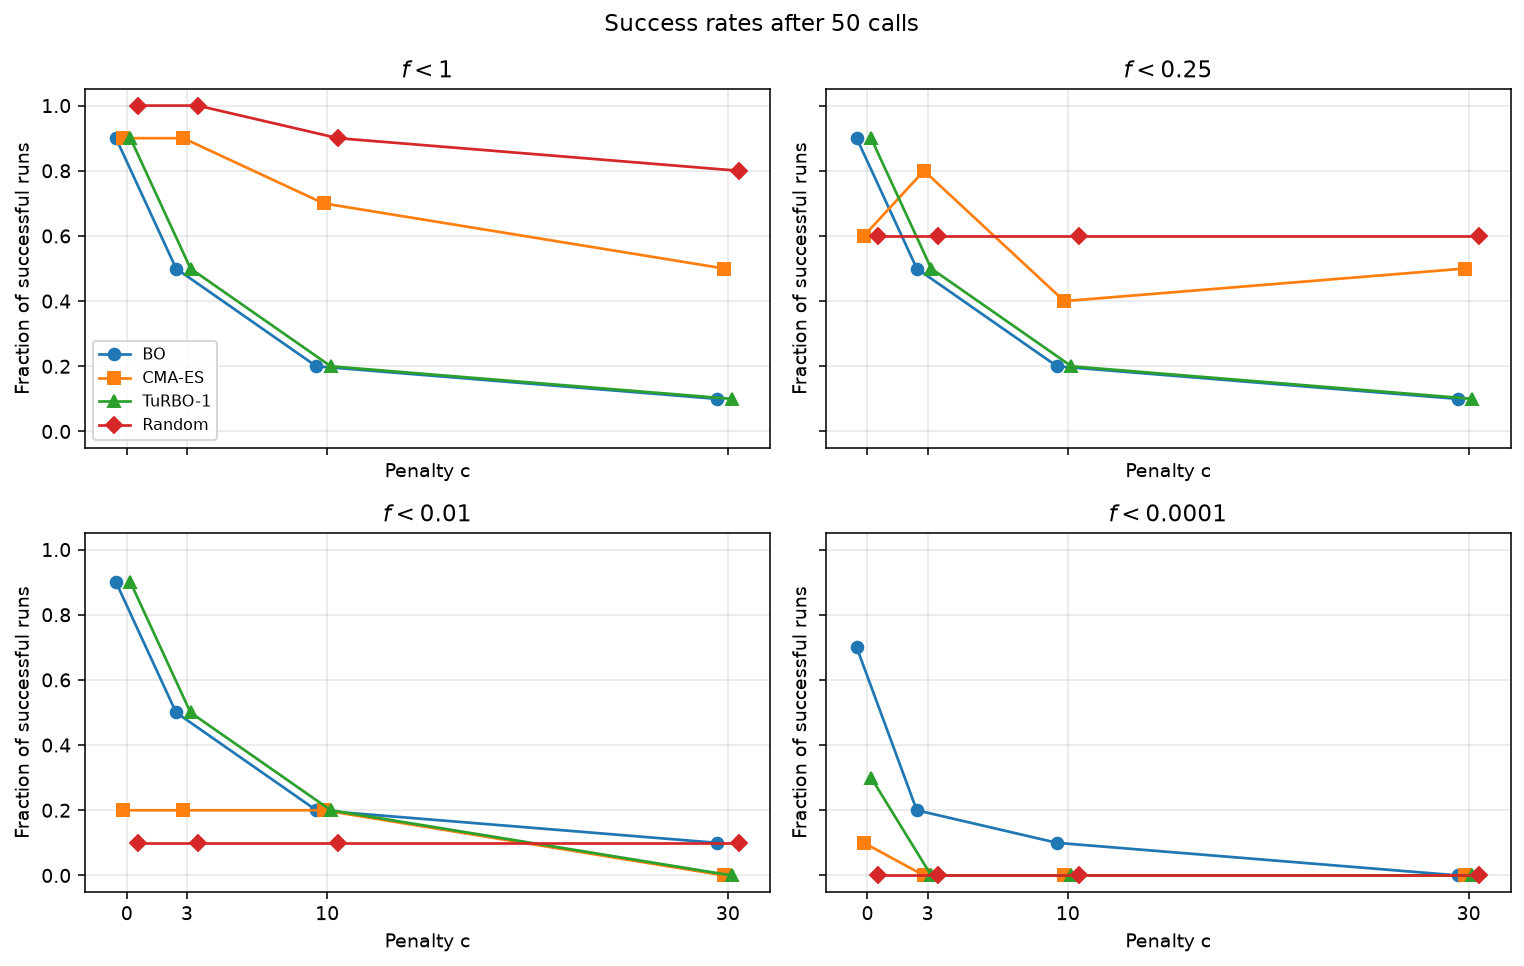

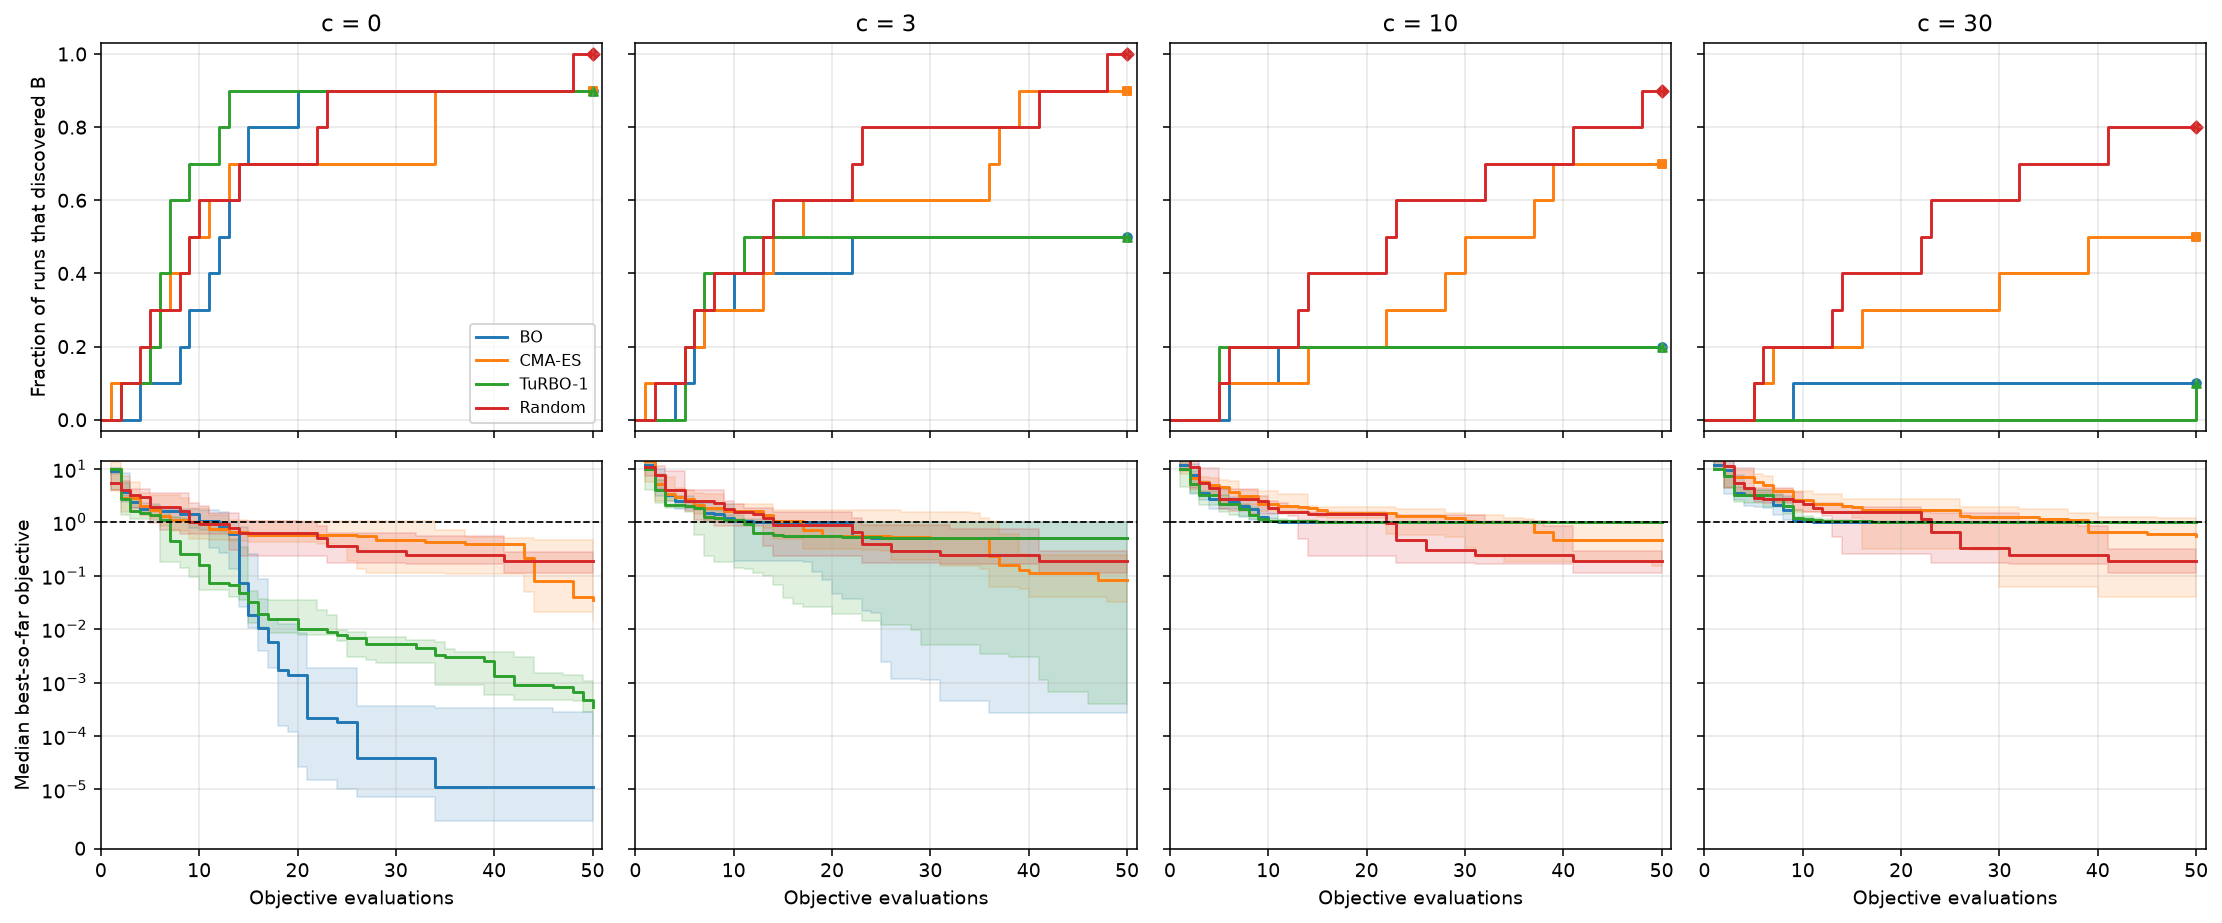

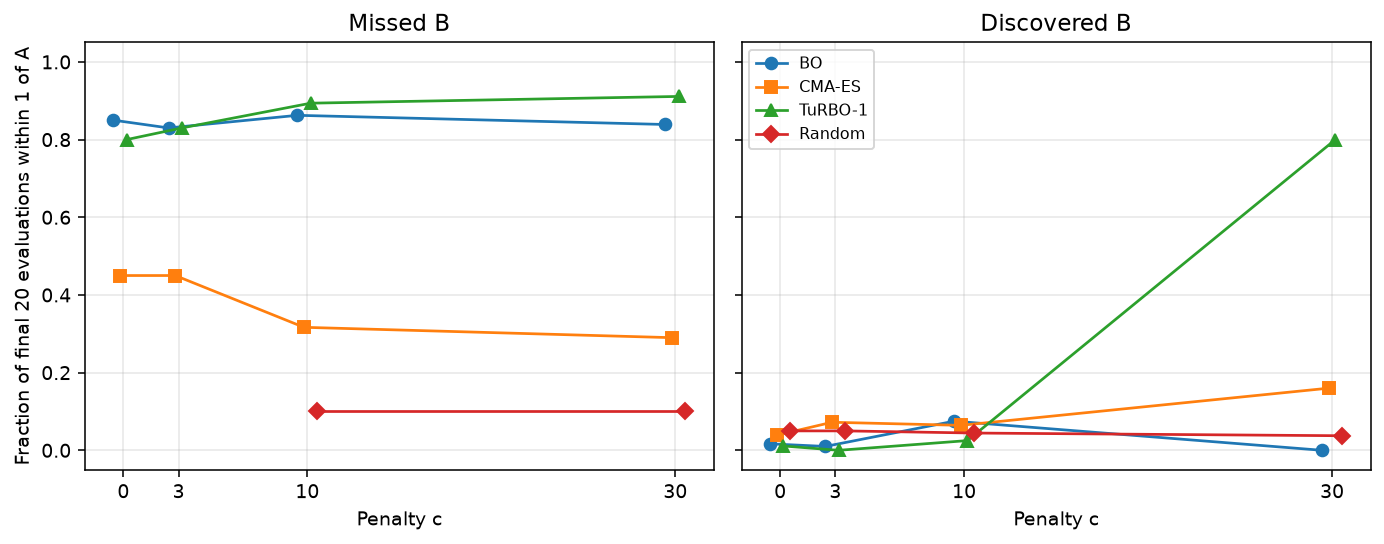

In [8]:
concentration = diagnostics.groupby(["c", "method", "discovered"]).agg(
    runs=("seed", "size"),
    mean_late_near_a=("late_near_a", "mean"),
    median_best=("best", "median"),
).reset_index()

hits = diagnostics.loc[diagnostics["discovered"]].assign(
    reached_0_01=lambda rows: rows["best"] < 0.01,
    hit_after_half=lambda rows: rows["first_discovery"] > RUN_SETTINGS["budget"] / 2,
)

refinement = hits.groupby(["c", "method"]).agg(
    discoveries=("seed", "size"),
    median_first_discovery=("first_discovery", "median"),
    discoveries_after_half=("hit_after_half", "sum"),
    median_calls_left=("calls_after_discovery", "median"),
    reached_0_01=("reached_0_01", "sum"),
)
display(concentration.round(6))
display(refinement)
concentration.to_csv(run_dir / "concentration.csv", index=False)
refinement.to_csv(run_dir / "refinement.csv")

cma_runs = diagnostics.loc[diagnostics["method"] == "CMA-ES", "restarts"].dropna()
print(f"CMA-ES started again in {(cma_runs > 0).sum()}/{len(cma_runs)} runs.")

plot_target_rates(summary, RUN_SETTINGS, run_dir)
plot_progress(results, diagnostics, RUN_SETTINGS, run_dir)
plot_concentration(concentration, RUN_SETTINGS, ANALYSIS_SETTINGS, run_dir)

**Graph 1**: Increasing c reduces the probability of beating A for all three adaptive methods. BO and TuRBO-1 decline from 9/10 to 5/10, 2/10 and 1/10. CMA-ES declines from 9/10 to 9/10, 7/10 and 5/10. CMA-ES therefore retains a higher discovery rate on the harder settings in this experiment. Its advantage becomes smaller or disappears when
success requires a more precise solution.

**Graph 2**: At c = 10, BO and TuRBO-1 make all their discoveries by call 11 and then remain flat. CMA-ES continues making discoveries through call 39. This suggests that the later evaluations of BO and TuRBO-1 rarely rescue runs that initially miss B under these settings.

**Graph 3**: Among runs that miss B at c = 30, BO and TuRBO-1 spend approximately 84% and 91% of their last 20 evaluations within distance 1 of A. The corresponding fraction for CMA-ES is 29%. These results are consistent with stronger late concentration near A for unsuccessful BO and TuRBO-1 runs. 

The successful TuRBO-1 group at c = 30 contains one run. It discovers B on call 50, which explains why it can both succeed and spend most of its final evaluations near A.

## 5. Map trajectories

At the largest $c$, show the lowest-numbered seed in each outcome group for each optimiser. Points show objective evaluations, coloured by their evaluation number. The ring marks the best point found. The dashed red circle bounds the region where $f<1$, and the dotted red circle marks the fixed center. 

In [9]:
from matplotlib.patches import Circle

def plot_trajectories(results, settings, c_value, run_dir):
    """Plot one discovered and one missed trajectory per optimiser at the chosen c."""

    methods = [m for m in settings["methods"] if m != "Random"]
    problem = settings["problem"]
    a, b = np.asarray(problem["a"]), np.asarray(problem["b"])
    bounds = np.asarray(problem["bounds"])
    r0 = problem["r0"]
    budget = settings["budget"]

    x, y = np.meshgrid(*(np.linspace(lo, hi, 250) for lo, hi in bounds))
    d_a = np.hypot(x - a[0], y - a[1])
    d_b = np.hypot(x - b[0], y - b[1])
    values = np.minimum(1 + d_a**2, d_b**2 + c_value * np.maximum(0, d_b - r0)**2)

    discovery_radius = (c_value * r0 + np.sqrt(1 + c_value * (1 - r0**2))) / (1 + c_value)

    norm = plt.Normalize(1, budget)
    palette = "viridis"

    fig, axes = plt.subplots(2, len(methods), figsize=(4 * len(methods) + 0.5, 8),
                             squeeze=False, constrained_layout=True)
    fig.get_layout_engine().set(h_pad=0.12)
    runs = [run for run in results["runs"] if run["c"] == c_value]
    for col, method in enumerate(methods):

        candidates = sorted((run for run in runs if run["method"] == method),
                            key=lambda run: run["seed"])
        for row, discovered in enumerate((False, True)):
            ax = axes[row, col]
            ax.contour(x, y, values, levels=[0.05, 0.25, 0.5, 1, 2, 4, 8, 16, 32],
                       colors="0.82", linewidths=0.65)
            ax.add_patch(Circle(b, discovery_radius, fill=False, color="tab:red", ls="--", lw=1.1))
            ax.add_patch(Circle(b, r0, fill=False, color="tab:red", ls=":", lw=1.1))
            ax.scatter(*a, color="black", marker="X", s=52, zorder=3)
            ax.scatter(*b, color="tab:red", marker="*", s=90, zorder=3)
            outcome = "Discovered B" if discovered else "Missed B"

            run = next((r for r in candidates if (min(r["y"]) < 1) == discovered), None)
            if run is None:
                ax.set(title=f"{method}: no {outcome.lower()} runs",
                       xlim=bounds[0], ylim=bounds[1], aspect="equal", ylabel="$x_2$")
                if row == 1:
                    ax.set_xlabel("$x_1$")
                continue
            points = np.asarray(run["X"])
            history = np.asarray(run["y"])
            best = int(np.argmin(history))
            ax.scatter(*points.T, c=np.arange(1, len(points) + 1), cmap=palette, norm=norm,
                       s=24, alpha=0.9, zorder=4)

            ax.scatter(*points[best], facecolors="none", edgecolors="black",
                       s=105, linewidths=1, zorder=5)
            hits = np.flatnonzero(history < 1)
            hit = f", first hit {hits[0] + 1}" if hits.size else ""
            ax.set_title(f"{method},{outcome},seed {run['seed']}\n"
                         f"best = {history[best]:.6g}{hit}")
            ax.set(xlim=bounds[0], ylim=bounds[1], aspect="equal", ylabel="$x_2$")
            if row == 1:
                ax.set_xlabel("$x_1$")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=palette), ax=axes,
                 shrink=0.72, label="Evaluation number")
    fig.suptitle(f"Example search trajectories at c = {c_value:g}")
    save_figure(fig, run_dir, "trajectories.png")

The next cell selects $c=30$ and draws the lowest-numbered missed and discovered seed for BO, CMA-ES, and TuRBO-1.

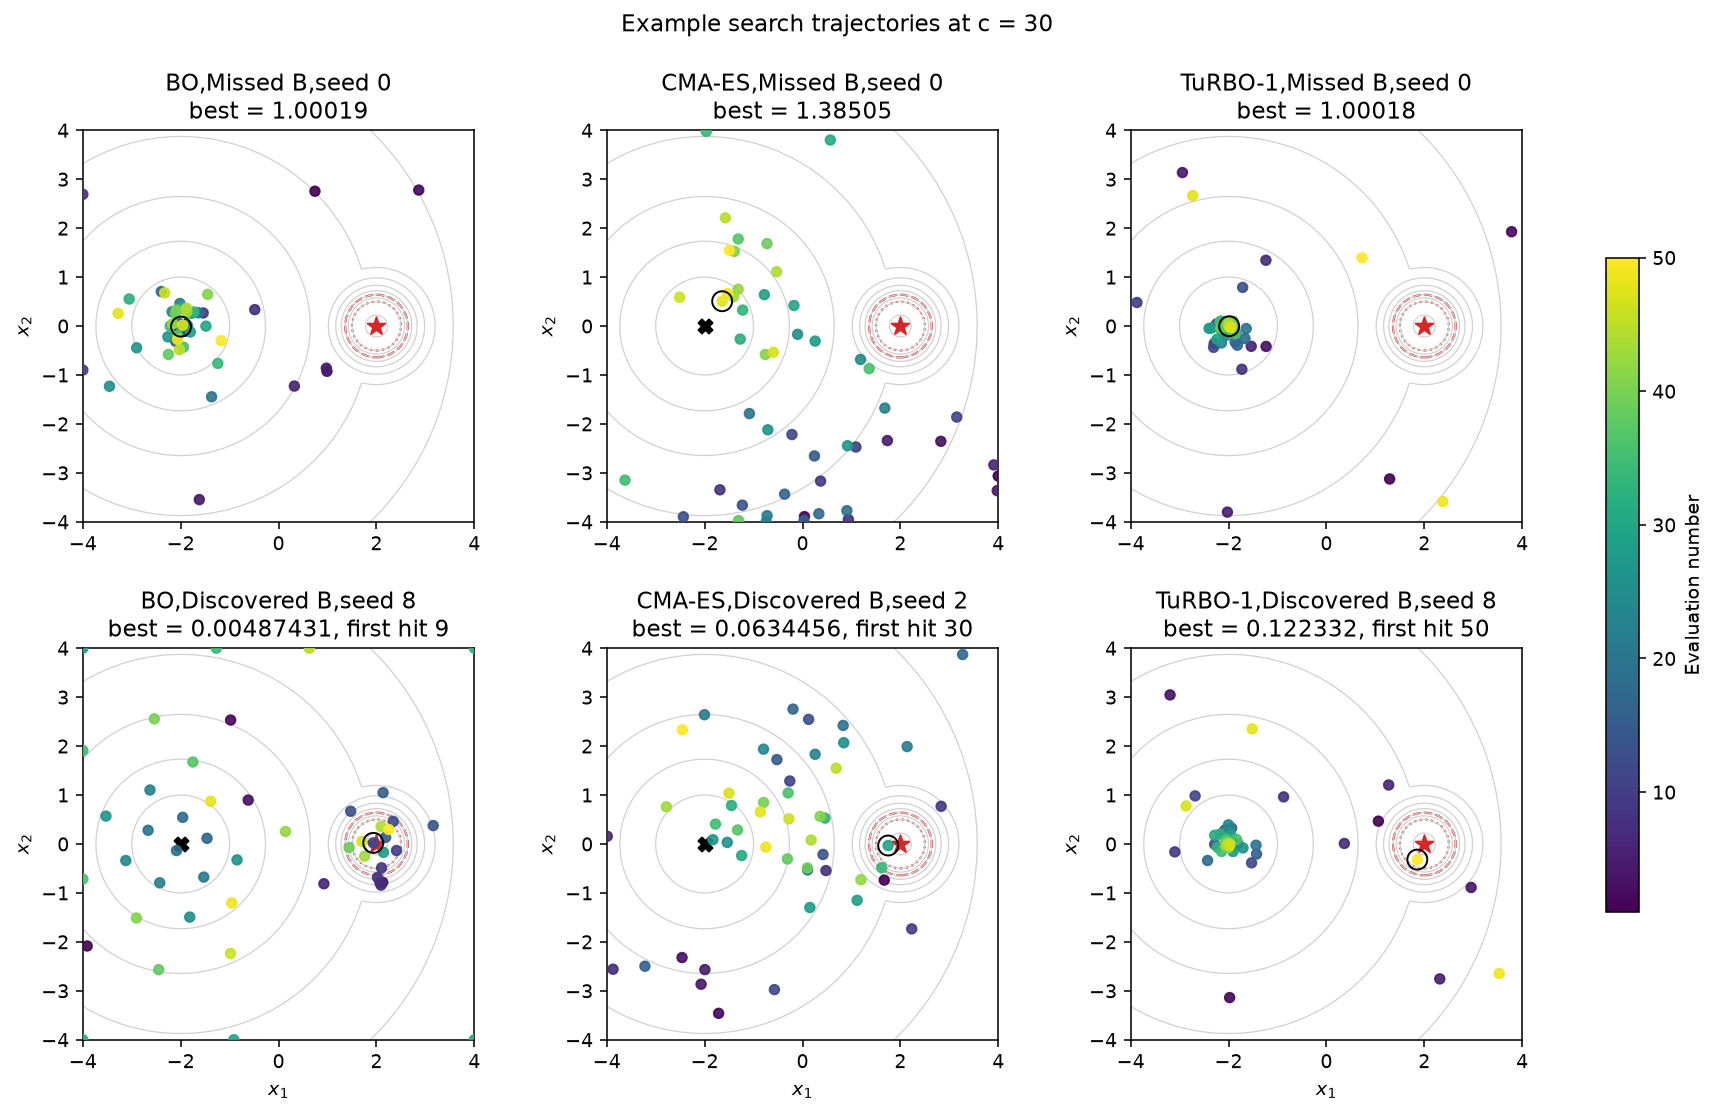

In [10]:
# Compare example outcomes at the largest configured penalty, where discovery is hardest.
trajectory_c = max(RUN_SETTINGS["c_values"])
plot_trajectories(results, RUN_SETTINGS, trajectory_c, run_dir)

## 6. Other comparisons


The next cell derives distance and refinement data. `closest_b` is the smallest Euclidean distance to B reached anywhere in a run. `center_call` is the first call strictly inside radius 0.5 of B, and `precise_call` is the first call with $f<0.01$. `trace_lookup` stores the cumulative minimum of the objective values for each penalty/method/seed. 

In [11]:
plot_settings = results["configuration"]["run"]
plot_cs = plot_settings["c_values"]
plot_methods = plot_settings["methods"]
plot_budget = plot_settings["budget"]
center_b = np.asarray(plot_settings["problem"]["b"])
center_radius = plot_settings["problem"]["r0"]


def first_hit(values, threshold):
    hits = np.flatnonzero(values < threshold)
    return float(hits[0] + 1) if hits.size else np.nan


def beat_a_radius(c):
    return (c * center_radius + np.sqrt(1 + c * (1 - center_radius**2))) / (1 + c)


extra_rows, trace_lookup = [], {}
for run in results["runs"]:
    values = np.asarray(run["y"])
    distance_b = np.linalg.norm(np.asarray(run["X"]) - center_b, axis=1)
    trace_lookup[run["c"], run["method"], run["seed"]] = np.minimum.accumulate(values)
    extra_rows.append({
        "c": run["c"], "method": run["method"], "seed": run["seed"],
        "closest_b": distance_b.min(),
        "center_call": first_hit(distance_b, center_radius),
        "precise_call": first_hit(values, 0.01),
    })
extra = pd.DataFrame(extra_rows)

### Compare approach to B at fixed distances

The next cell plots, for each penalty and method, the fraction of runs whose closest evaluated point to B was within distance $r$. A curve farther left means more runs approached B closely. The dotted line is the fixed center radius, while the dashed line is the penalty-dependent radius at which the objective drops below A's minimum. The displayed table gives the number of runs that entered the radius-0.5 center and the number that approached within distance 1. 

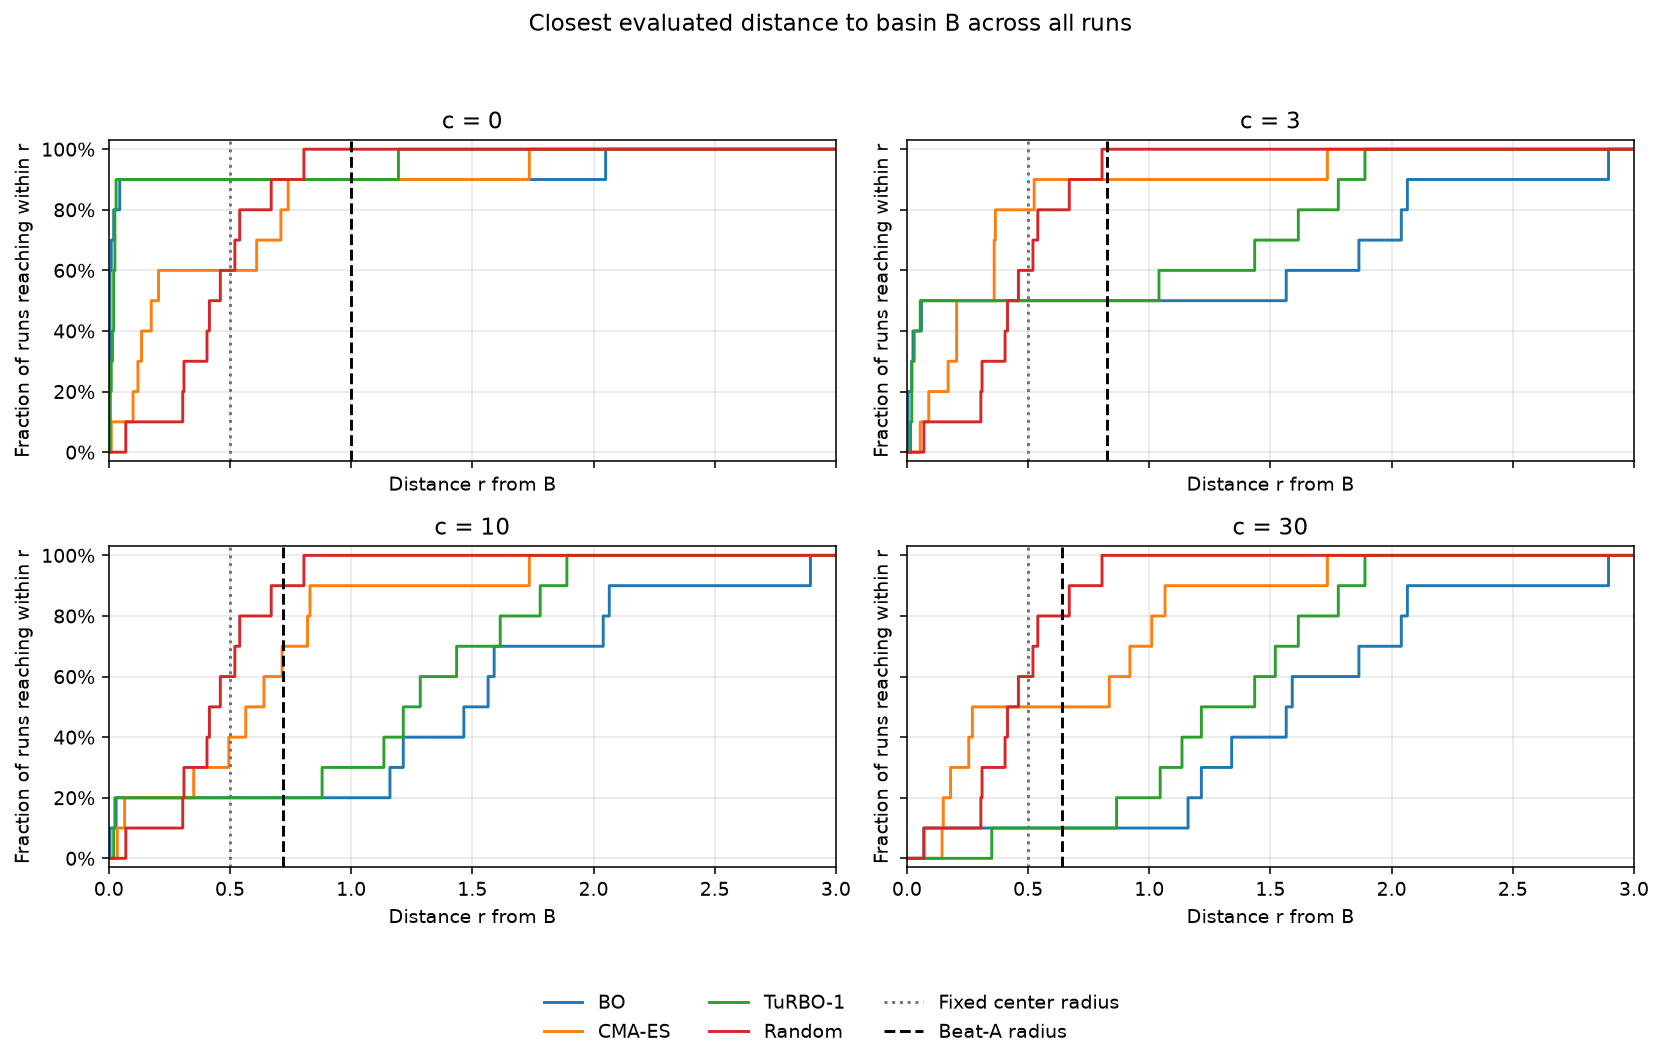

runs  entered_center  reached_distance_1
c    method                                           
0.0  BO         10               9                   9
     CMA-ES     10               6                   9
     Random     10               6                  10
     TuRBO-1    10               9                   9
3.0  BO         10               5                   5
     CMA-ES     10               8                   9
     Random     10               6                  10
     TuRBO-1    10               5                   5
10.0 BO         10               2                   2
     CMA-ES     10               4                   9
     Random     10               6                  10
     TuRBO-1    10               2                   3
30.0 BO         10               1                   1
     CMA-ES     10               5                   7
     Random     10               6                  10
     TuRBO-1    10               1                   2

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.6), sharex=True, sharey=True)
radius_limit = float(np.ceil(extra["closest_b"].max()))
radius_grid = np.linspace(0, radius_limit, 601)
for ax, c in zip(axes.flat, plot_cs):
    for method in plot_methods:
        distances = extra.loc[(extra["c"] == c) & (extra["method"] == method),
                              "closest_b"].to_numpy()
        fractions = (distances[:, None] <= radius_grid).mean(axis=0)
        ax.step(radius_grid, fractions, where="post", color=METHOD_STYLES[method][0],
                label=method)
    ax.axvline(center_radius, color="0.45", linestyle=":", label="Fixed center radius")
    ax.axvline(beat_a_radius(c), color="black", linestyle="--", label="Beat-A radius")
    ax.set(title=f"c = {c:g}", xlim=(0, radius_limit), ylim=(-0.03, 1.03),
           xlabel="Distance r from B", ylabel="Fraction of runs reaching within r")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.3)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Closest evaluated distance to basin B across all runs")
fig.tight_layout(rect=(0, 0.10, 1, 0.95))
save_figure(fig, run_dir, "closest_approach_to_b.png")

fixed_radius_table = extra.assign(
    within_center=extra["closest_b"] < center_radius,
    within_one=extra["closest_b"] < 1.0,
).groupby(["c", "method"]).agg(
    runs=("seed", "size"), entered_center=("within_center", "sum"),
    reached_distance_1=("within_one", "sum"),
)
display(fixed_radius_table)

Each curve gives the fraction of runs that sampled at least one point within distance $r$ of $b$. The dotted line marks the fixed radius $0.5$, and the dashed line marks the radius within which an evaluation beats A's minimum of 1. Comparing methods at a fixed distance separates changes in where they sample from changes in the radius required to beat A.

At distance 1, BO went from 9/10 runs approaching B at $c=0$ to 1/10 at $c=30$. TuRBO-1 went from 9/10 to 2/10, while CMA-ES went from 9/10 to 7/10. The harder landscapes therefore changed where the adaptive methods sampled. At $c=30$, all five CMA-ES runs that beat A entered B's fixed center on the same evaluation. Their precision failures persisted even after reaching this intermediate target.

### Refinement after center entry

For runs that entered B's center, each line is the run's best-so-far objective from then until the budget ends. Downward steps indicate improvements, crosses mark the final available evaluation, and the dashed horizontal line is the precision target $f=0.01$. The table reports center-entry counts, median calls remaining after entry, and the number reaching the precision target.

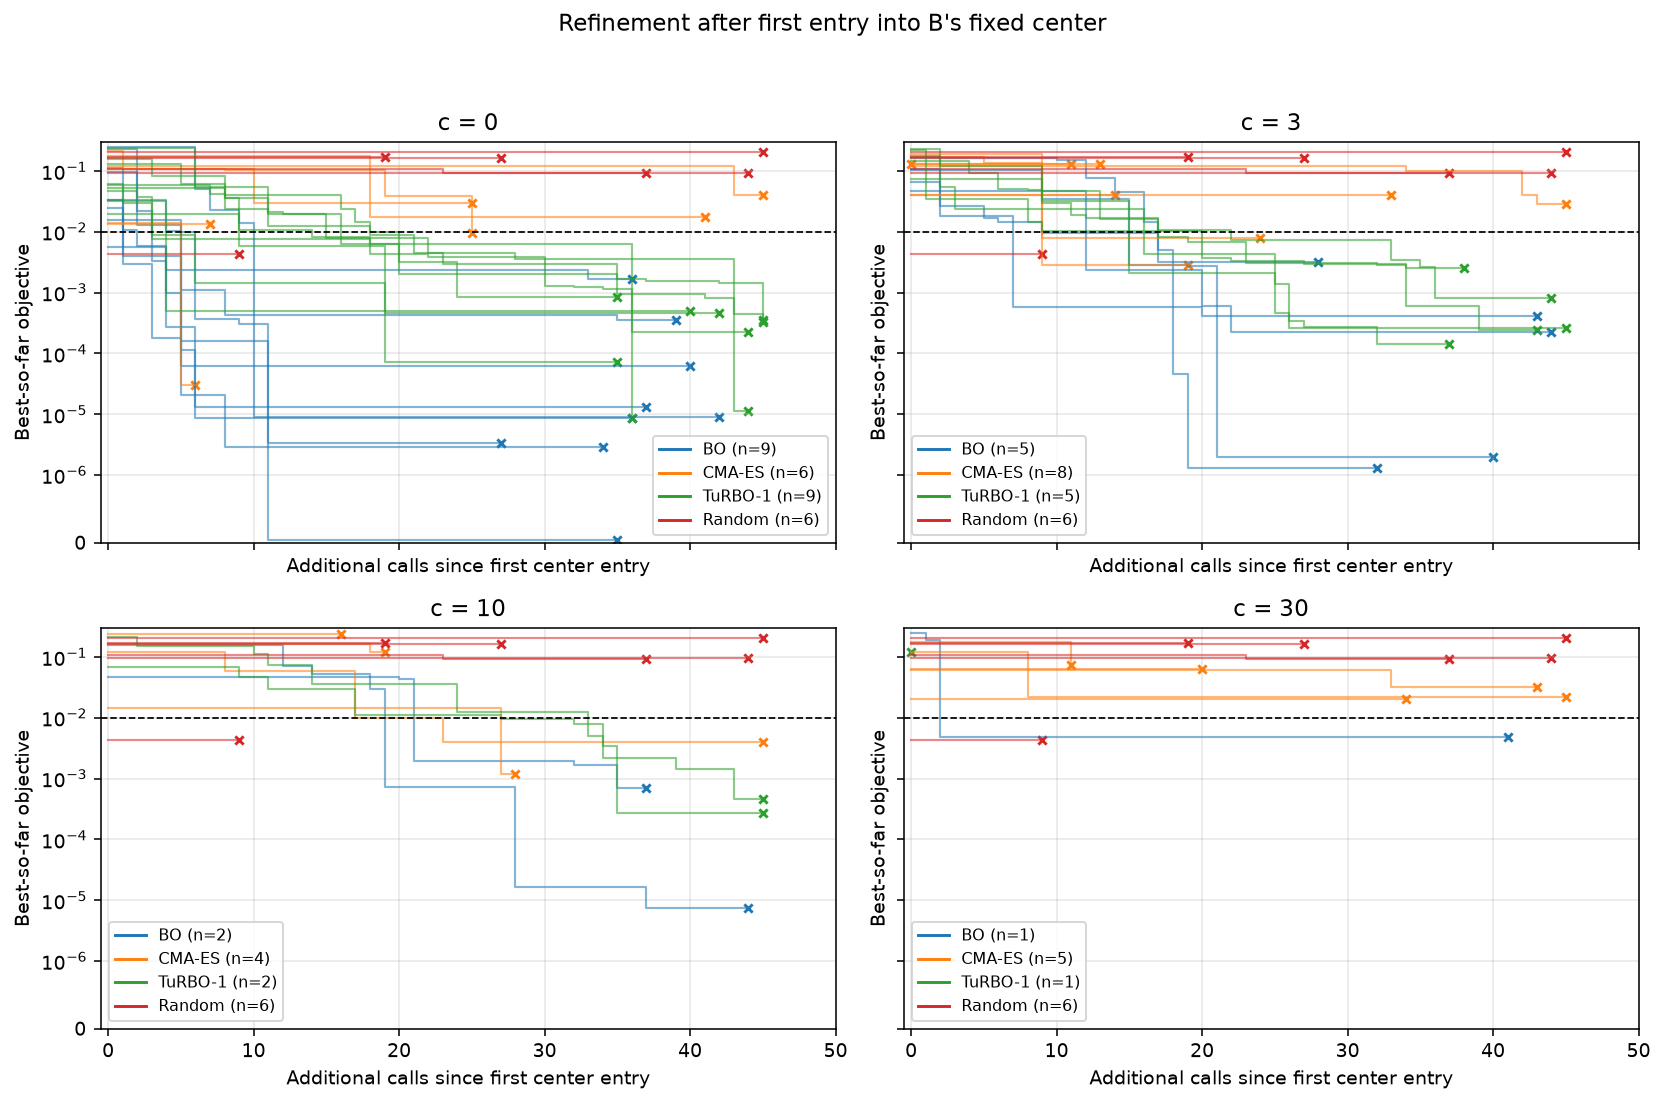

center_entries  median_calls_left  reached_0_01
c    method                                                  
0.0  BO                    9               36.0             9
     CMA-ES                6               25.0             2
     Random                6               32.0             1
     TuRBO-1               9               42.0             9
3.0  BO                    5               40.0             5
     CMA-ES                8               16.5             2
     Random                6               32.0             1
     TuRBO-1               5               43.0             5
10.0 BO                    2               40.5             2
     CMA-ES                4               23.5             2
     Random                6               32.0             1
     TuRBO-1               2               45.0             2
30.0 BO                    1               41.0             1
     CMA-ES                5               34.0             0
     Random                6               32.0             1
     TuRBO-1               1                0.0             0

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, c in zip(axes.flat, plot_cs):
    for method in plot_methods:
        color = METHOD_STYLES[method][0]
        entered = extra.loc[(extra["c"] == c) & (extra["method"] == method)
                            & extra["center_call"].notna()].sort_values("seed")
        ax.plot([], [], color=color, label=f"{method} (n={len(entered)})")
        for row in entered.itertuples():
            best = trace_lookup[row.c, row.method, row.seed][int(row.center_call) - 1:]
            calls = np.arange(len(best))
            ax.step(calls, best, where="post", color=color, alpha=0.55, linewidth=1.1)
            ax.scatter(calls[-1], best[-1], color=color, marker="x", s=18)
    ax.axhline(0.01, color="black", linestyle="--", linewidth=0.9)
    ax.set_yscale("symlog", linthresh=1e-6)
    ax.set(title=f"c = {c:g}", xlim=(-0.5, plot_budget), ylim=(0, 0.3),
           xlabel="Additional calls since first center entry", ylabel="Best-so-far objective")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Refinement after first entry into B's fixed center")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_figure(fig, run_dir, "refinement_after_center_entry.png")

center_runs = extra.loc[extra["center_call"].notna()].assign(
    calls_left=lambda df: plot_budget - df["center_call"],
    reached_0_01=lambda df: df["precise_call"].notna(),
)
display(center_runs.groupby(["c", "method"]).agg(
    center_entries=("seed", "size"), median_calls_left=("calls_left", "median"),
    reached_0_01=("reached_0_01", "sum"),
))

Time zero is the first evaluation inside the center, defined by $f<0.25$. Downward steps mark improvements in the best observed value. At $c=0$, BO, TuRBO-1 and CMA-ES each beat A in nine runs. BO and TuRBO-1 reached $f<0.01$ in all nine of their discoveries, while CMA-ES reached that target in two. 

At $c=30$, CMA-ES entered the center in five runs and reached $f<0.01$ in none. Seed 2 entered on call 30 and never sampled inside the center again. Seed 4 entered on call 7, evaluated eight more points inside the
center, and improved from about $0.0608$ to $0.0317$. Some failures therefore involved difficulty returning to the center, while others persisted despite multiple opportunities to refine inside it.

The sole BO run that entered the center at $c=30$ reached $f<0.01$ two calls later. The sole TuRBO-1 run entered on call 50, leaving zero calls for refinement. 


### Final results

**The methods ranked differently on discovery and precision.** Discovery means finding a point with $f_c(x)<1$, which beats the minimum in basin A. Precision means reaching $f_c(x)<0.01$, which requires evaluating within $0.1$ of the global minimiser $b$. Each entry gives **discoveries / precise solutions** out of 10 runs, with 50 evaluations per run.

| Outer penalty $c$ | BO-EI | CMA-ES | TuRBO-1 | Uniform random |
|---:|---:|---:|---:|---:|
| 0 | 9 / 9 | 9 / 2 | 9 / 9 | 10 / 1 |
| 3 | 5 / 5 | 9 / 2 | 5 / 5 | 10 / 1 |
| 10 | 2 / 2 | 7 / 2 | 2 / 2 | 9 / 1 |
| 30 | 1 / 1 | 5 / 0 | 1 / 0 | 8 / 1 |

**Discovery became the main bottleneck for BO-EI and TuRBO-1 as the outer penalty increased.** At $c=10$, both methods made their only discoveries by call 11. CMA-ES discovered B in seven runs, four of them after call 25. At $c=30$, among runs that failed to beat A, BO-EI and TuRBO-1 spent about 84% and 91% of their final 20 evaluations within distance 1 of A, respectively. The corresponding figure for CMA-ES was 29%. Uniform random search maintained coverage of the whole domain and had the highest observed discovery rate at every penalty. It reached the much smaller precision target in only one run per setting.

**CMA-ES often found B without refining to high precision.** At $c=0$, all three adaptive methods discovered B in nine runs, but BO-EI and TuRBO-1 reached precision in all nine, compared with two for CMA-ES. At $c=10$, CMA-ES discovered B in seven runs versus two for each BO method, yet all three reached precision in two runs. At $c=30$, five CMA-ES runs entered B's fixed radius-$0.5$ centre and none reached precision. One entered on call 7 and evaluated eight more points inside the centre, improving from about $0.0608$ to $0.0317$. That early entry suggests that limited time after discovery explains only part of the refinement difficulty. The sole BO-EI run that entered the centre at $c=30$ reached precision two calls later. TuRBO-1's sole entry came on call 50.

### Hypotheses for Experiment 2

- **BO-EI discovery.** For runs that have yet to beat A after 12 calls, reserving some evaluations for global probes should increase the probability of discovering B by call 50. Experiment 2A tests this by comparing different continuations from the same search history.
- **CMA-ES discovery and refinement.** One candidate entering B does not guarantee that the sampling distribution concentrates there. Experiment 2B varies population size, parent count, domain geometry, initial spread, and update rules from matched starts near A and B. Its main normalised initial step size is $0.30$, with physical-spread comparisons of 2.4 and 12 in the wider domain. Experiment 3 supplies a shared evaluated initial design and compares the Experiment 1 scale $\sigma_0=0.25$ with $\sigma_0=0.05$ from the same best initial point.
